# Histogramas de supervivientes y desintegrados

- Simula $M=500$ simulaciones con $N_0=10^3$.
- Toma tres instantes:
  - $t_I=T_{1/2}/20$
  - $t_{II}=T_{1/2}$
  - $t_{III}=5 · T_{1/2}$
- Construye los histogramas de:
  - $N_I, N_{II}, N_{III}$
  - $D_I, D_{II}, D_{III}$
- Superpone la predicción binomial y la aproximación de Poisson.
- Genera una tabla de momentos teóricos.


In [22]:
import matplotlib.pyplot as plt
import numpy as np
import time
import csv
import pandas as pd

from IPython.display import display, HTML

from scipy.stats import binom, poisson, chisquare
from matplotlib.ticker import MultipleLocator

# ============================================================
# CONSTANTES FÍSICAS Y PARÁMETROS DE LA SIMULACIÓN
# ============================================================

# Vida media. 
T12 = 5  # años

# Constante de desintegración
Lambda = np.log(2) / T12

n0 = 5*10**3              # número inicial de núcleos
M = 500                 # número de trayectorias/simulaciones

# Instantes (Diccionario que incluye los instantes de tiempo que vamos a usar)
instantes = {
    "I": T12 / 20,
    "II": T12,
    "III": 5 * T12
}

# Paso y número de pasos
dt = 0.05

t_max = max(instantes.values())
u = int(round(t_max / dt))

if u==0: #si hacemos una división agresiva se redondea a 0 por lo que le damos el valor uno
    u=1

# Probabilidad de supervivencia en un paso dt
q_step = np.exp(-Lambda * dt)

# Probabilidad de desintegración en un paso dt
p_step = 1 - q_step

# Posiciones de los instantes en la simulación (redondeadas al entero más cercano)
posiciones = {}

for clave, tiempo in instantes.items():
    posicion = int(round(tiempo / dt))
    posiciones[clave] = posicion


print("Lambda =", Lambda)
print("dt =", dt)
print("q_step =", q_step)
print("p_step =", p_step)
print("Posiciones de los instantes:", posiciones)


Lambda = 0.13862943611198905
dt = 0.05
q_step = 0.9930924954370359
p_step = 0.006907504562964073
Posiciones de los instantes: {'I': 5, 'II': 100, 'III': 500}


In [23]:
def simulacion():
    
    supervivientes = np.zeros(u + 1, dtype=int)
    supervivientes[0] = n0

    N = n0

    for j in range(1, u + 1):
        N = np.random.binomial(N, q_step)
        supervivientes[j] = N

    return supervivientes


inicio = time.perf_counter()

# matriz con M simulaciones y u+1 tiempos
matriz_N = np.zeros((M, u + 1), dtype=int)

for m in range(M):
    matriz_N[m, :] = simulacion()

fin = time.perf_counter()

# matriz de desintegrados
matriz_D = n0 - matriz_N

print(f"Tiempo de ejecución: {fin - inicio:.2f} s")


Tiempo de ejecución: 0.22 s


In [24]:
# ============================================================
# EXTRAER LOS 6 CASOS:
# N_I, N_II, N_III, D_I, D_II, D_III
# ============================================================

datos = {}

for clave, pos in posiciones.items():
    datos[f"N_{clave}"] = matriz_N[:, pos] #RECORDATORIO: f sirve para meter variables dentro de strings
    datos[f"D_{clave}"] = matriz_D[:, pos]

# Orden de las columnas para mostrar los datos
orden_columnas = ["N_I", "N_II", "N_III", "D_I", "D_II", "D_III"]


# Guardar los datos. la w indica que se abre el csv para escribir, y f es el nombre del archivo que le doy para llamarlo luego.
with open("histogramas_N_D_500_trayectorias.csv", "w", newline="") as f:  
    writer = csv.writer(f)
    writer.writerow(orden_columnas)

    for i in range(M):
        writer.writerow([datos[col][i] for col in orden_columnas])


In [25]:
# ============================================================
# FUNCIONES TEÓRICAS
# ============================================================

def parametros_teoricos(variable, clave):
    t_i = instantes[clave]
    q = np.exp(-Lambda * t_i)

    if variable == "N":
        p_bin = q
    elif variable == "D":
        p_bin = 1 - q
    else:
        raise ValueError("variable debe ser 'N' o 'D'")

    media_bin = n0 * p_bin
    var_bin = n0 * p_bin * (1 - p_bin)

    # Poisson aproximante
    media_poi = media_bin
    var_poi = media_poi

    return {
        "t": t_i,
        "p_bin": p_bin,
        "media_bin": media_bin,
        "var_bin": var_bin,
        "sigma_bin": np.sqrt(var_bin),
        "media_poi": media_poi,
        "var_poi": var_poi,
        "sigma_poi": np.sqrt(var_poi)
    }


def numero_bines_scott(muestra):
    """
    Regla de Scott:
        h = 3.5*sigma*M^(-1/3)

    Devuelve:
        bines: número de bines
        anchura: anchura aproximada del bin
    """
    muestra = np.asarray(muestra)
    sigma = np.std(muestra, ddof=1)

    if sigma == 0:
        return 1, 1

    h = 3.5 * sigma * len(muestra)**(-1/3)
    rango = muestra.max() - muestra.min()

    if rango == 0:
        return 1, 1

    bines = int(np.ceil(rango / h))

    if bines < 1:
        bines = 1

    # Lo dejamos impar, como estabas haciendo
    if bines % 2 == 0:
        bines += 1

    anchura = rango / bines

    return bines, anchura


# ============================================================
# CACHE DE HISTOGRAMAS
# ============================================================
# Aquí se guardan los bines de Scott de cada columna.
# Así la tabla, el chi cuadrado y las gráficas usan EXACTAMENTE
# los mismos edges y no se recalcula el número de bines por separado.

histogramas_scott = {}


def obtener_histograma_scott(col, muestra):
    """
    Calcula una sola vez el histograma de una columna usando Scott.

    Devuelve un diccionario con:
        - bines
        - anchura
        - edges
        - frecuencia_observada

    Si ya estaba calculado, lo reutiliza.
    """
    if col not in histogramas_scott:
        muestra = np.asarray(muestra)

        bines, anchura_scott = numero_bines_scott(muestra)
        frecuencia_observada, edges = np.histogram(muestra, bins=bines)

        # np.histogram con bins entero usa bins de anchura constante.
        if len(edges) > 1:
            anchura_real = edges[1] - edges[0]
        else:
            anchura_real = anchura_scott

        histogramas_scott[col] = {
            "bines": bines,
            "anchura": anchura_real,
            "edges": edges,
            "frecuencia_observada": frecuencia_observada
        }

    return histogramas_scott[col]


def frecuencias_esperadas_por_bin(edges, variable, clave, distribucion, num_datos):
    """
    Calcula las frecuencias esperadas E_i para cada bin del histograma.

    IMPORTANTE:
    - Los datos son enteros: número de núcleos supervivientes o desintegrados.
    - Por eso no se evalúa la distribución en el centro del bin.
    - Se suma la probabilidad teórica de todos los valores enteros k que caen dentro de cada bin.
    - num_datos es el número total de simulaciones usadas en el histograma.
    """

    pars = parametros_teoricos(variable, clave)
    esperadas = []

    for i in range(len(edges) - 1):

        izquierda = edges[i]
        derecha = edges[i + 1]

        # En np.histogram:
        # - todos los bins son [izquierda, derecha)
        # - el último bin incluye también el borde derecho
        if i < len(edges) - 2:
            k_min = int(np.ceil(izquierda))
            k_max = int(np.ceil(derecha) - 1)
        else:
            k_min = int(np.ceil(izquierda))
            k_max = int(np.floor(derecha))

        if k_max < k_min:
            prob_bin = 0.0
        else:
            k = np.arange(k_min, k_max + 1)

            if distribucion == "binomial":
                prob_bin = np.sum(binom.pmf(k, n0, pars["p_bin"]))

            elif distribucion == "poisson":
                prob_bin = np.sum(poisson.pmf(k, pars["media_poi"]))

            else:
                raise ValueError("distribucion debe ser 'binomial' o 'poisson'")

        esperadas.append(num_datos * prob_bin)

    return np.array(esperadas, dtype=float)


# ============================================================
# FUNCIÓN PARA CALCULAR CHI CUADRADO Y P-VALUE POR BINES
# ============================================================

def chi2_y_pvalue(edges, frecuencia_observada, variable, clave, distribucion, ddof):
    """
    Calcula chi cuadrado y p-value usando los edges ya calculados.

    Esto evita recalcular el número de bines dentro de la función.
    Por tanto, el chi cuadrado, la tabla y las gráficas usan los mismos bines.

    Procedimiento:
        1. Recibe O_i y edges del histograma experimental ya calculado.
        2. Calcula E_i = frecuencia esperada teórica en cada bin.
        3. Reescala E_i para que sum(E_i) = sum(O_i).
        4. Calcula chi2 = sum_i (O_i - E_i)^2 / E_i.
        5. Calcula el p-value con scipy.stats.chisquare.

    Grados de libertad:
        scipy usa gl = k - 1 - ddof

    En este notebook:
        ddof = 2 para binomial
        ddof = 1 para Poisson
    """

    frecuencia_observada = np.asarray(frecuencia_observada, dtype=float)
    num_datos = frecuencia_observada.sum()

    frecuencia_esperada = frecuencias_esperadas_por_bin(
        edges=edges,
        variable=variable,
        clave=clave,
        distribucion=distribucion,
        num_datos=num_datos
    )

    # Factor de normalización:
    # Obliga a que la suma de esperadas coincida con la suma de observadas.
    # Es necesario porque puede quedar una pequeña probabilidad teórica fuera
    # del rango cubierto por los bins del histograma.
    if frecuencia_esperada.sum() > 0:
        frecuencia_esperada = frecuencia_esperada * num_datos / frecuencia_esperada.sum()

    # Quitamos bins con E_i = 0 para evitar divisiones por cero.
    mascara = frecuencia_esperada > 0

    O = frecuencia_observada[mascara]
    E = frecuencia_esperada[mascara]

    # Al quitar bins con E_i = 0, volvemos a igualar las sumas.
    if E.sum() > 0:
        E = E * O.sum() / E.sum()

    dof = len(O) - 1 - ddof

    # Si quedan muy pocos bins, el test no tiene sentido.
    if len(O) < 2 or dof <= 0:
        return np.nan, np.nan, dof, O, E, frecuencia_esperada

    chi2, p_value = chisquare(
        f_obs=O,
        f_exp=E,
        ddof=ddof
    )

    return chi2, p_value, dof, O, E, frecuencia_esperada


In [26]:
# ============================================================
# TABLAS SEPARADAS: BINOMIAL Y POISSON
# ============================================================

# Nombres internos de las filas.
# Se usan nombres sencillos para construir y ordenar el DataFrame.
filas = [
    "E",
    "sqrt_var",
    "media_muestral",
    "desviacion_muestral",
    "chi2",
    "p_value"
]

tabla_binomial = {}
tabla_poisson = {}

for col in orden_columnas:

    variable, clave = col.split("_")
    pars = parametros_teoricos(variable, clave)
    muestra = datos[col]

    # Estadísticos muestrales
    media_muestral = np.mean(muestra)
    desviacion_muestral = np.std(muestra, ddof=1)

    # Histograma de Scott calculado una sola vez para esta muestra
    info_hist = obtener_histograma_scott(col, muestra)
    edges = info_hist["edges"]
    frecuencia_observada = info_hist["frecuencia_observada"]

    # Chi cuadrado y p-value para la binomial
    chi2_bin, p_bin, dof_bin, O_bin, E_bin, E_bin_completa = chi2_y_pvalue(
        edges=edges,
        frecuencia_observada=frecuencia_observada,
        variable=variable,
        clave=clave,
        distribucion="binomial",
        ddof=2
    )

    # Chi cuadrado y p-value para Poisson
    chi2_poi, p_poi, dof_poi, O_poi, E_poi, E_poi_completa = chi2_y_pvalue(
        edges=edges,
        frecuencia_observada=frecuencia_observada,
        variable=variable,
        clave=clave,
        distribucion="poisson",
        ddof=1
    )

    # Tabla binomial
    tabla_binomial[col] = {
        "E": pars["media_bin"],
        "sqrt_var": np.sqrt(pars["var_bin"]),
        "media_muestral": media_muestral,
        "desviacion_muestral": desviacion_muestral,
        "chi2": chi2_bin,
        "p_value": p_bin
    }

    # Tabla de Poisson
    tabla_poisson[col] = {
        "E": pars["media_poi"],
        "sqrt_var": np.sqrt(pars["var_poi"]),
        "media_muestral": media_muestral,
        "desviacion_muestral": desviacion_muestral,
        "chi2": chi2_poi,
        "p_value": p_poi
    }


# ==================================================σ==========
# CREAR LOS DATAFRAMES CON PANDAS
# ============================================================

df_binomial = pd.DataFrame(tabla_binomial).loc[filas, orden_columnas]
df_poisson = pd.DataFrame(tabla_poisson).loc[filas, orden_columnas]


# ============================================================
# NOMBRES VISUALES CON SUBÍNDICES Y SUPERÍNDICES
# ============================================================

nombres_columnas = {
    "N_I": "N<sub>I</sub>",
    "N_II": "N<sub>II</sub>",
    "N_III": "N<sub>III</sub>",
    "D_I": "D<sub>I</sub>",
    "D_II": "D<sub>II</sub>",
    "D_III": "D<sub>III</sub>"
}

nombres_filas = {
    "E": "E",
    "sqrt_var": "√Var",
    "media_muestral": "N&#772;",
    "desviacion_muestral": "σ&#772;",
    "chi2": "χ<sup>2</sup>",
    "p_value": "<i>p</i>-value"
}

df_binomial_visual = df_binomial.rename(
    columns=nombres_columnas,
    index=nombres_filas
)

df_poisson_visual = df_poisson.rename(
    columns=nombres_columnas,
    index=nombres_filas
)

df_binomial_visual.index.name = None
df_poisson_visual.index.name = None


# ============================================================
# MOSTRAR UNA TABLA PANDAS CENTRADA
# ============================================================
# No se usa df.style, por lo que no hace falta instalar Jinja2.
# pandas crea el HTML mediante DataFrame.to_html().

def mostrar_tabla_pandas(df, titulo):

    # Formato de seis decimales sin alterar los valores originales
    df_formateado = df.map(
        lambda valor: f"{valor:.6f}"
        if isinstance(valor, (int, float, np.integer, np.floating))
        else valor
    )

    tabla_html = df_formateado.to_html(
        escape=False,
        border=0
    )

    html = f"""
    <h3 style="text-align:left;">{titulo}</h3>

    <style>
        table.dataframe {{
            border-collapse: collapse;
            margin-top: 10px;
        }}

        table.dataframe th,
        table.dataframe td {{
            text-align: center !important;
            vertical-align: middle !important;
            padding: 7px 12px;
        }}
    </style>

    {tabla_html}
    """

    display(HTML(html))


mostrar_tabla_pandas(
    df_binomial_visual,
    "TABLA DE LA DISTRIBUCIÓN BINOMIAL"
)

mostrar_tabla_pandas(
    df_poisson_visual,
    "TABLA DE LA DISTRIBUCIÓN DE POISSON"
)


# ============================================================
# GUARDAR EN CSV
# ============================================================

df_binomial.to_csv(
    "tabla_binomial.csv",
    encoding="utf-8-sig",
    index_label="Magnitud"
)

df_poisson.to_csv(
    "tabla_poisson.csv",
    encoding="utf-8-sig",
    index_label="Magnitud"
)


# ============================================================
# GUARDAR EN LÁTEX
# ============================================================
# Se genera el archivo .tex manualmente para evitar errores con
# pandas.to_latex() y dependencias como Jinja2.

nombres_columnas_latex = {
    "N_I": r"$N_I$",
    "N_II": r"$N_{II}$",
    "N_III": r"$N_{III}$",
    "D_I": r"$D_I$",
    "D_II": r"$D_{II}$",
    "D_III": r"$D_{III}$"
}

nombres_filas_latex = {
    "E": r"$E(X)$",
    "sqrt_var": r"$\sigma$",
    "media_muestral": r"$\overline{X}$",
    "desviacion_muestral": r"$s$",
    "chi2": r"$\chi^2$",
    "p_value": r"$p$-value"
}


def guardar_tabla_latex(df, nombre_archivo):

    with open(nombre_archivo, "w", encoding="utf-8") as f:

        ncols = len(df.columns)

        # Primera columna: magnitud. Luego las columnas de datos.
        formato_columnas = "c|" + "c" * ncols

        f.write(r"\begin{tabular}{" + formato_columnas + "}\n")
        f.write(r"\hline" + "\n")

        # Cabecera
        cabecera = ["Magnitud"] + [
            nombres_columnas_latex[col] for col in df.columns
        ]

        f.write(" & ".join(cabecera) + r" \\" + "\n")
        f.write(r"\hline" + "\n")

        # Filas
        for indice, fila in df.iterrows():

            valores = [nombres_filas_latex[indice]]

            for valor in fila:
                if isinstance(valor, (int, float, np.integer, np.floating)):
                    valores.append(f"{valor:.3f}")
                else:
                    valores.append(str(valor))

            f.write(" & ".join(valores) + r" \\" + "\n")

        f.write(r"\hline" + "\n")
        f.write(r"\end{tabular}" + "\n")


guardar_tabla_latex(df_binomial, "tabla_binomial.tex")
guardar_tabla_latex(df_poisson, "tabla_poisson.tex")


,NI,NII,NIII,DI,DII,DIII
E,4829.681645,2500.000000,156.250000,170.318355,2500.000000,4843.750000
√Var,12.826406,35.355339,12.303137,12.826406,35.355339,12.303137
N̄,4829.336000,2502.882000,156.580000,170.664000,2497.118000,4843.420000
σ̄,12.601615,34.978494,11.884531,12.601615,34.978494,11.884531
χ2,13.592127,13.660001,11.377572,13.592127,13.660001,11.377572
p-value,0.327509,0.322945,0.496868,0.327509,0.322945,0.496868


,NI,NII,NIII,DI,DII,DIII
E,4829.681645,2500.000000,156.250000,170.318355,2500.000000,4843.750000
√Var,69.495911,50.000000,12.500000,13.050607,50.000000,69.597055
N̄,4829.336000,2502.882000,156.580000,170.664000,2497.118000,4843.420000
σ̄,12.601615,34.978494,11.884531,12.601615,34.978494,11.884531
χ2,302.259376,75.441201,11.768141,13.440683,74.493309,360.835809
p-value,0.000000,0.000000,0.546742,0.414377,0.000000,0.000000


## Interpretación $\chi^2$ y grados de libertad

Ahora el cálculo se hace **por bines del histograma**, no por cada valor entero individual de $k$.

Primero se calculan los bines con la regla de Scott. Después, para cada bin $i$:

$$
O_i = \text{número experimental de simulaciones que caen en el bin } i,
$$

$$
E_i = \text{número esperado según la distribución teórica en ese mismo bin}.
$$

Entonces:

$$
\chi^2 = \sum_i \frac{(O_i-E_i)^2}{E_i}.
$$

Aquí:

- $O_i$ sale directamente del histograma experimental.
- $E_i$ se obtiene sumando la probabilidad teórica de todos los valores enteros $k$ que caen dentro de ese bin.
- La función usa los **mismos edges** para la tabla, el cálculo de $\chi^2$ y las gráficas.

Los grados de libertad se toman como:

$$
\nu = k - 1 - r,
$$

donde:

- $k$ es el número de bines usados.
- El $-1$ aparece por la normalización $\sum_i O_i = \sum_i E_i$.
- $r$ es el número de parámetros de la distribución.

Por tanto:

$$
\nu_{\mathrm{Poi}} = k - 1 - 1 = k-2,
$$

$$
\nu_{\mathrm{Bin}} = k - 1 - 2 = k-3.
$$

En `scipy.stats.chisquare`, ese $-1$ ya está incluido internamente. Por eso en el código se usa:

```python
# Binomial
chisquare(f_obs=O, f_exp=E, ddof=2)

# Poisson
chisquare(f_obs=O, f_exp=E, ddof=1)
```


## Interpretación $p$-value

De forma práctica:

- Si $p > 0.05$, no hay evidencia estadística suficiente para rechazar el modelo teórico. El ajuste se considera razonable.
- Si $p \approx 0.05$, el resultado está en una zona límite.
- Si $p < 0.05$, existen diferencias significativas entre la simulación y el modelo teórico.
- Si $p \ll 0.05$, el ajuste es claramente malo o el test se está aplicando de forma demasiado estricta.

In [27]:
# ============================================================
# FUNCIÓN PARA REPRESENTAR HISTOGRAMAS EN VERTICAL
# (3 filas x 1 columna)
# ============================================================

def representar_histogramas_vertical(lista_columnas, nombre_archivo, titulo_general):
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 19))

    for ax, col in zip(axes, lista_columnas):

        muestra = datos[col]

        variable, clave = col.split("_")
        pars = parametros_teoricos(variable, clave)

        media_muestral = np.mean(muestra)
        sigma_muestral = np.std(muestra, ddof=1)

        # Bines calculados con Scott
        info_hist = obtener_histograma_scott(col, muestra)
        edges = info_hist["edges"]
        anchurabin = info_hist["anchura"]

        # Rango entero para las distribuciones teóricas
        k_min = int(muestra.min())
        k_max = int(muestra.max())
        k = np.arange(k_min, k_max + 1)

        # Frecuencias teóricas
        frecuencia_binomial = M * binom.pmf(k, n0, pars["p_bin"])
        frecuencia_poisson = M * poisson.pmf(k, pars["media_poi"])

        # ====================================================
        # HISTOGRAMA
        # ====================================================
        ax.hist(
            muestra,
            bins=edges,
            edgecolor="black",
            alpha=0.7,
            label="Simulación"
        )

        # ====================================================
        # DISTRIBUCIONES TEÓRICAS
        # ====================================================
        ax.plot(
            k,
            frecuencia_binomial * anchurabin,
            "-",
            label="Binomial teórica"
        )

        ax.plot(
            k,
            frecuencia_poisson * anchurabin,
            "--",
            label="Poisson teórica"
        )

        # ====================================================
        # MEDIA Y DESVIACIÓN MUESTRAL
        # ====================================================
        ax.axvline(
            media_muestral,
            color="red",
            linestyle="-",
            label=f"Media muestral = {media_muestral:.2f}"
        )

        ax.axvline(
            media_muestral + sigma_muestral,
            color="green",
            linestyle="-",
            label=fr"Media muestral $\pm~\overline{{\sigma}}$ = {sigma_muestral:.2f}"
        )

        ax.axvline(
            media_muestral - sigma_muestral,
            color="green",
            linestyle="-"
        )

        # ====================================================
        # MEDIA Y DESVIACIÓN TEÓRICA BINOMIAL
        # ====================================================
        ax.axvline(
            pars["media_bin"],
            color="blue",
            linestyle="-",
            label=f"Media teórica = {pars['media_bin']:.2f}"
        )

        ax.axvline(
            pars["media_bin"] + pars["sigma_bin"],
            color="orange",
            linestyle="-",
            label=f"Media teórica ± σ = {pars['sigma_bin']:.2f}"
        )

        ax.axvline(
            pars["media_bin"] - pars["sigma_bin"],
            color="orange",
            linestyle="-"
        )

        # ====================================================
        # CONFIGURACIÓN
        # ====================================================
        if variable == "N":
            nombre_variable = "supervivientes"
            etiqueta_x = "NÚCLEOS SUPERVIVIENTES"
        else:
            nombre_variable = "desintegrados"
            etiqueta_x = "NÚCLEOS DESINTEGRADOS"

        ax.set_title(
            f"{col}: {nombre_variable} en $t={pars['t']/T12:.2f}T_{{1/2}}$",
            fontsize=17,
            fontweight="normal"
        )

        ax.set_xlabel(etiqueta_x, fontsize=16)
        ax.set_ylabel("FRECUENCIA", fontsize=16)

        ax.tick_params(axis="both", which="major", labelsize=13)
        ax.tick_params(axis="both", which="minor", labelsize=11)

        rango_x = muestra.max() - muestra.min()

        # ====================================================
        # ESPACIADO DEL EJE X
        # ====================================================
        if rango_x > 1000:
            ax.xaxis.set_major_locator(MultipleLocator(200))
            ax.xaxis.set_minor_locator(MultipleLocator(100))
        elif rango_x > 400:
            ax.xaxis.set_major_locator(MultipleLocator(100))
            ax.xaxis.set_minor_locator(MultipleLocator(50))
        elif rango_x > 150:
            ax.xaxis.set_major_locator(MultipleLocator(50))
            ax.xaxis.set_minor_locator(MultipleLocator(25))
        elif rango_x > 50:
            ax.xaxis.set_major_locator(MultipleLocator(20))
            ax.xaxis.set_minor_locator(MultipleLocator(10))
        elif rango_x > 30:
            ax.xaxis.set_major_locator(MultipleLocator(10))
            ax.xaxis.set_minor_locator(MultipleLocator(5))
        else:
            ax.xaxis.set_major_locator(MultipleLocator(5))
            ax.xaxis.set_minor_locator(MultipleLocator(1))

        ax.grid(True, which="major", alpha=0.3)
        ax.grid(True, which="minor", alpha=0.1)

        ax.legend(
            fontsize=14,
            loc="upper right",
            frameon=True,
            labelspacing=0.5,
            handlelength=1.8,
            borderpad=0.6
        )

    fig.suptitle(titulo_general, fontsize=20, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.savefig(nombre_archivo, dpi=300, bbox_inches="tight")
    plt.show()

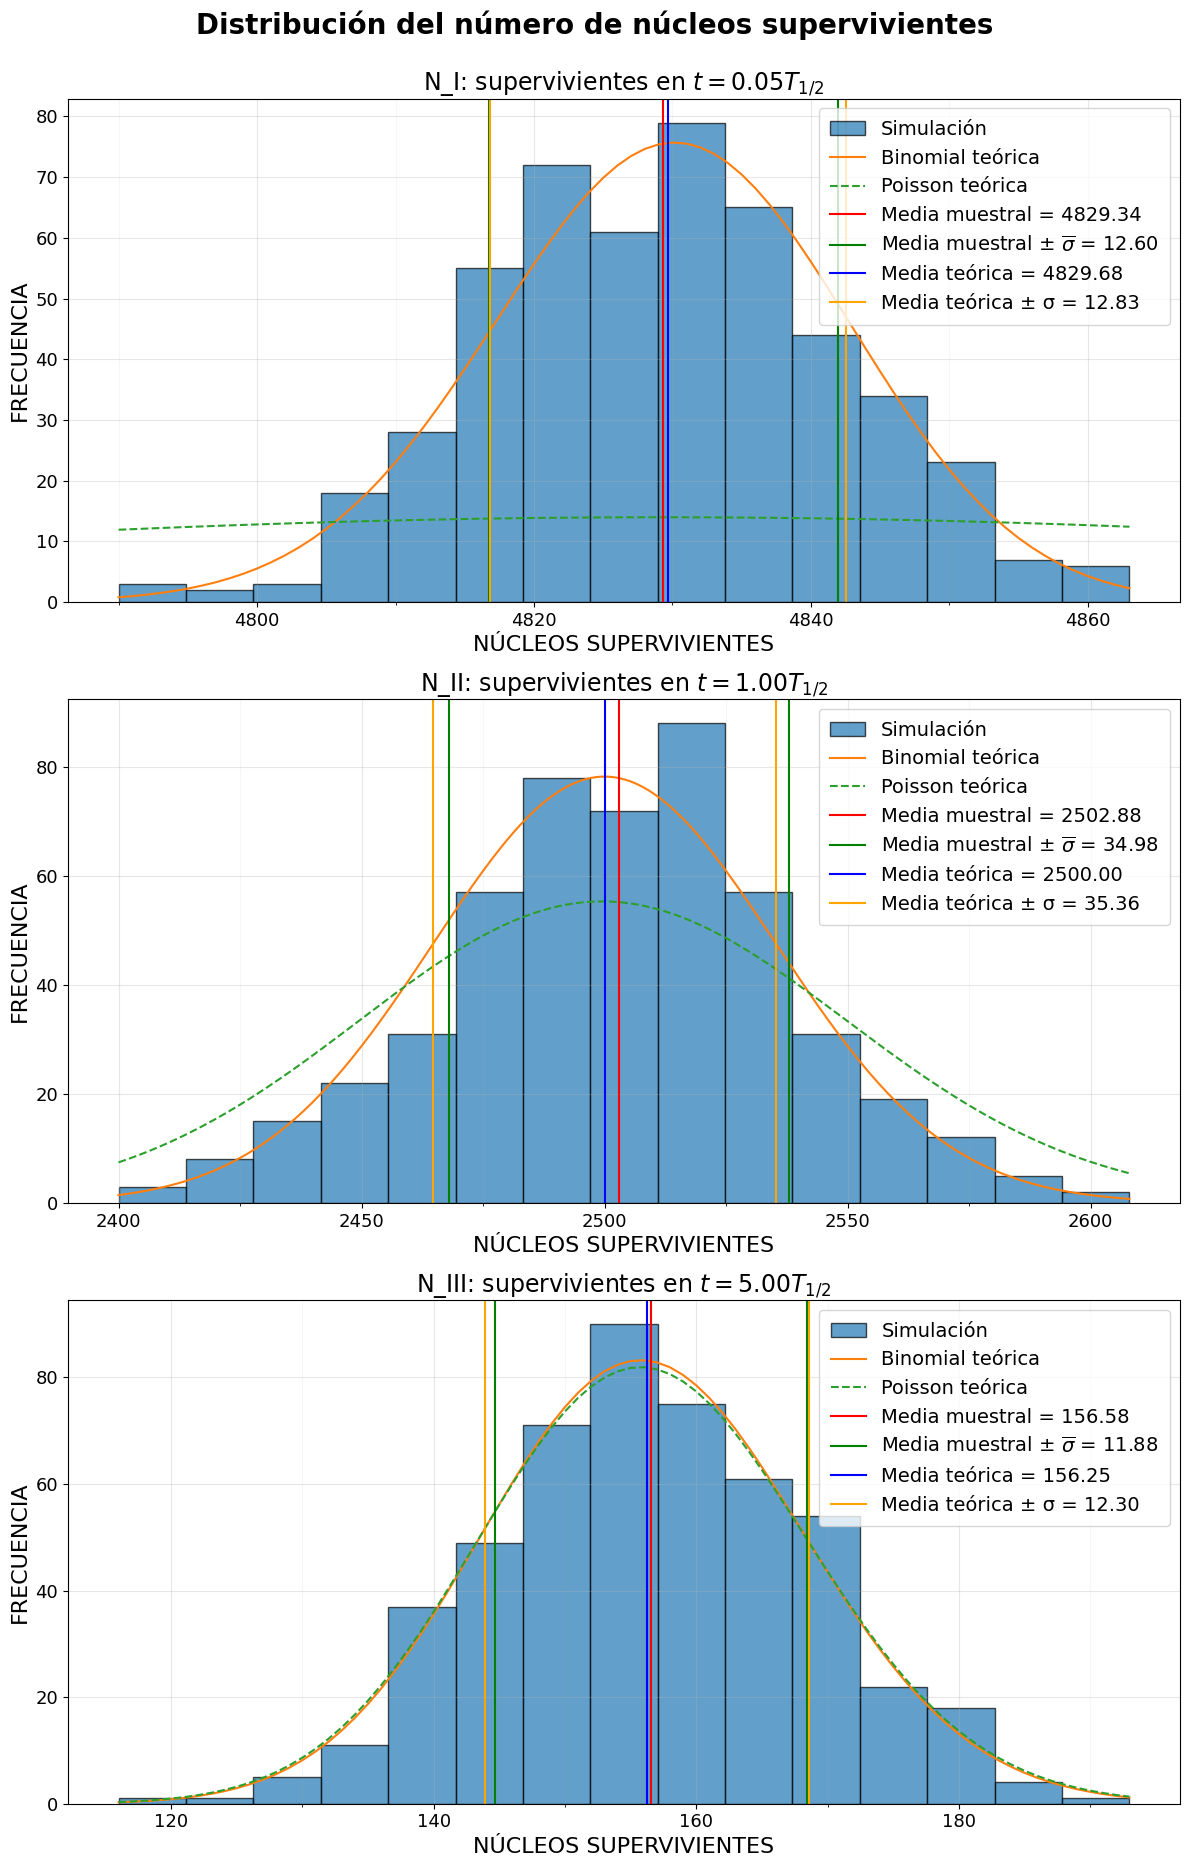

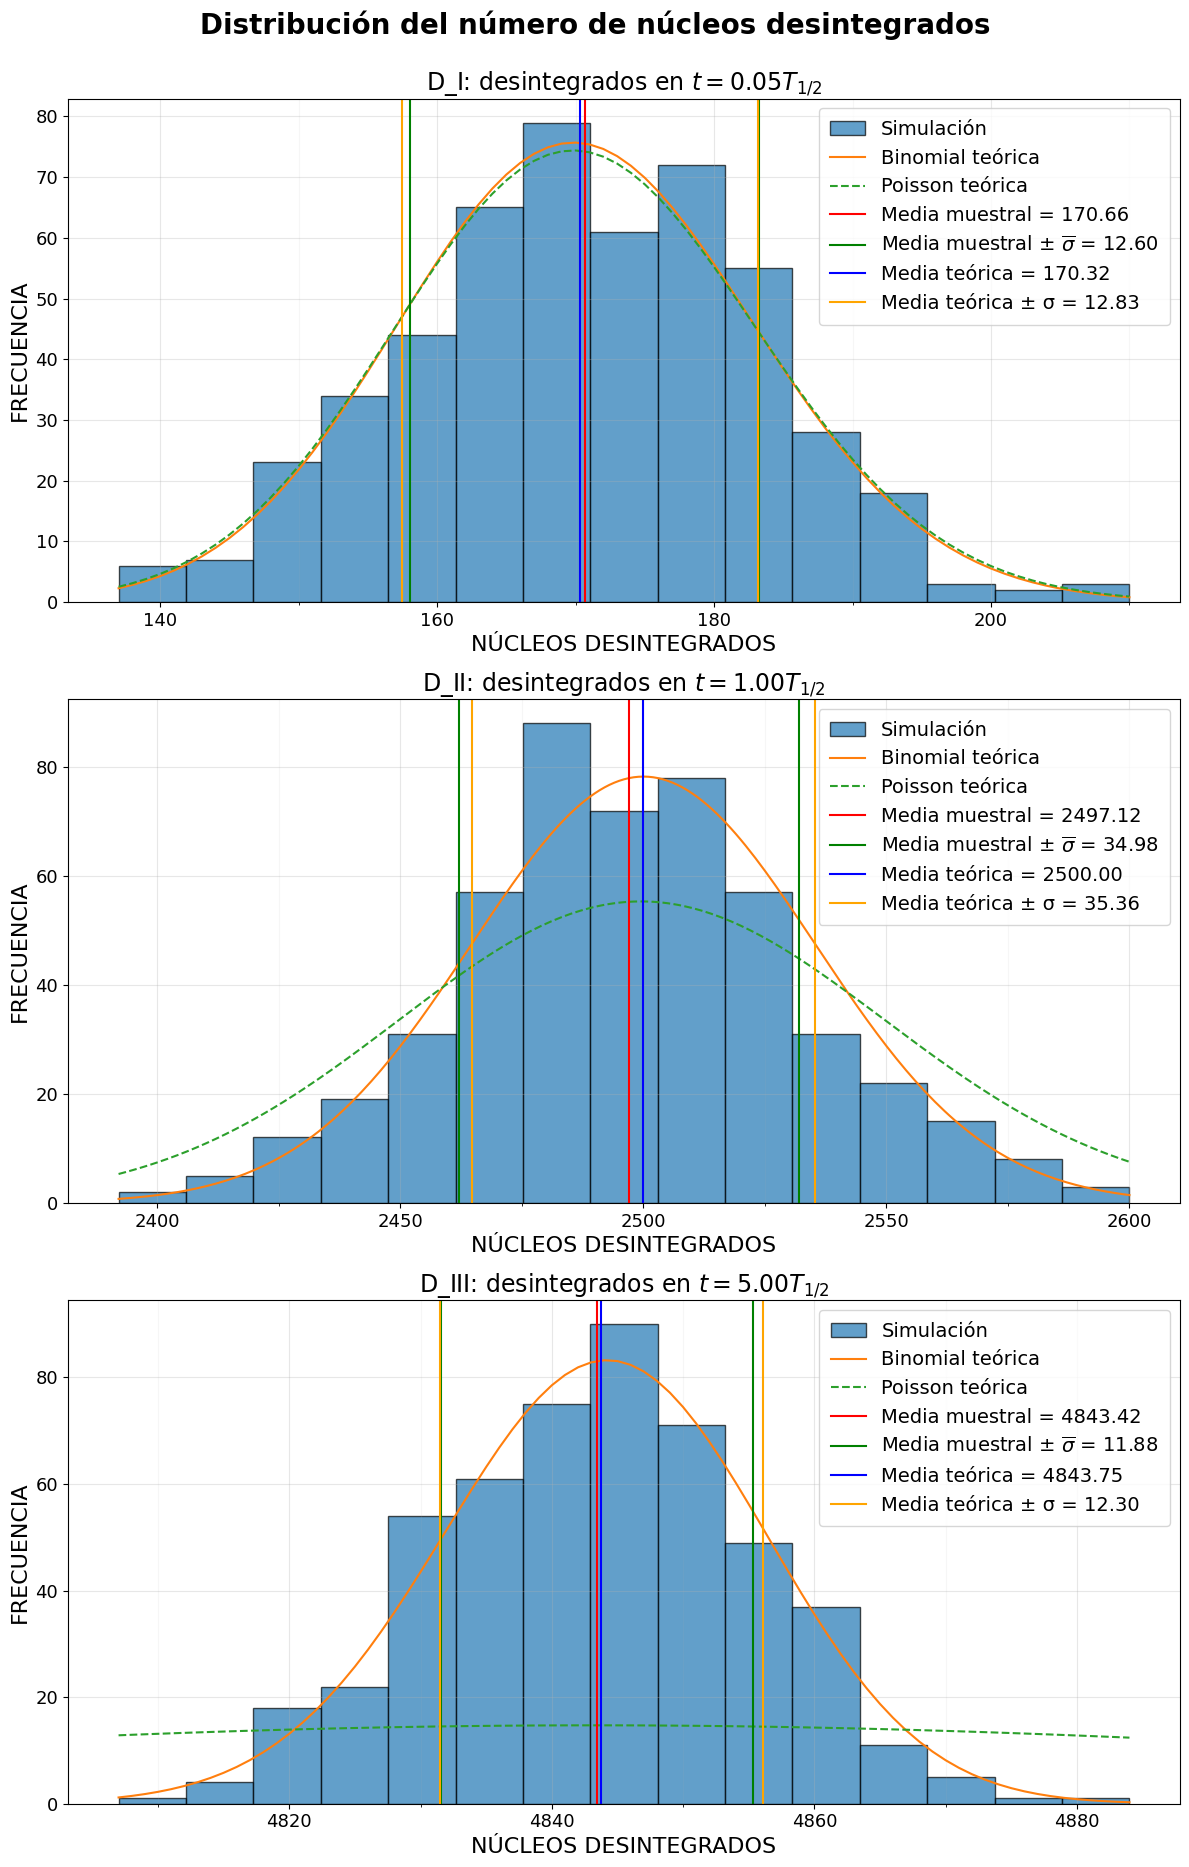

In [28]:
# ============================================================
# FIGURA 1: SUPERVIVIENTES
# ============================================================

representar_histogramas_vertical(
    lista_columnas=["N_I", "N_II", "N_III"],
    nombre_archivo="histogramas_supervivientes_vertical.png",
    titulo_general="Distribución del número de núcleos supervivientes"
)

# ============================================================
# FIGURA 2: DESINTEGRADOS
# ============================================================

representar_histogramas_vertical(
    lista_columnas=["D_I", "D_II", "D_III"],
    nombre_archivo="histogramas_desintegrados_vertical.png",
    titulo_general="Distribución del número de núcleos desintegrados"
)